In [85]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

### Question a

In [86]:
peer_grades = pd.read_csv('peerGrades.csv', names=['Grade'], header=None)
peer_grades.head()

,Grade
0,65
1,68
2,80
3,100
4,73


##### Compute the sample mean of peer grades

In [87]:
mean = peer_grades.mean()
mean

Grade    69.2296
dtype: float64

### Question b

##### Build PMF of the peer-grade

In [88]:
pmf = peer_grades['Grade'].value_counts().sort_index() / peer_grades['Grade'].value_counts().sum()
pmf

Grade
0      0.0636
1      0.0004
2      0.0011
3      0.0011
4      0.0006
        ...  
96     0.0019
97     0.0017
98     0.0013
99     0.0011
100    0.0396
Name: count, Length: 101, dtype: float64

##### Build funtion to simulate the extraction of 5 values and return the sample mean

In [89]:
def simulate():
    result = pd.Series(np.random.choice(a=pmf.index, p=pmf.values, size=5))
    return result.mean()
simulate()

np.float64(71.0)

##### Run simulation 1000 times to compute the variance of the sample mean

In [90]:
result1 = pd.Series([simulate() for _ in range(1000)])
print(f"The variance of sample mean is {result1.var()}")

The variance of sample mean is 98.20673073073081


### Problem c

##### Build funtion to simulate the extraction of 5 values and return the sample median

In [91]:
def simulate():
    result = pd.Series(np.random.choice(a=pmf.index, p=pmf.values, size=5))
    return result.median()
simulate()

68.0

##### Run simulation 1000 times to compute the variance of the sample median

In [92]:
result2 = pd.Series([simulate() for _ in range(1000)])
print(f"The variance of sample median is {result2.var()}")
result2.head()

The variance of sample median is 68.50703103103115


0    79.0
1    79.0
2    76.0
3    79.0
4    81.0
dtype: float64

### Problem d

##### Plot the distribution of the expected median

In [93]:
# Construct the PMF of the sample median
pmf2 = result2.value_counts().sort_index() / result2.value_counts().sum()
pmf2.head()

0.0     0.004
4.0     0.001
18.0    0.001
20.0    0.001
23.0    0.001
Name: count, dtype: float64

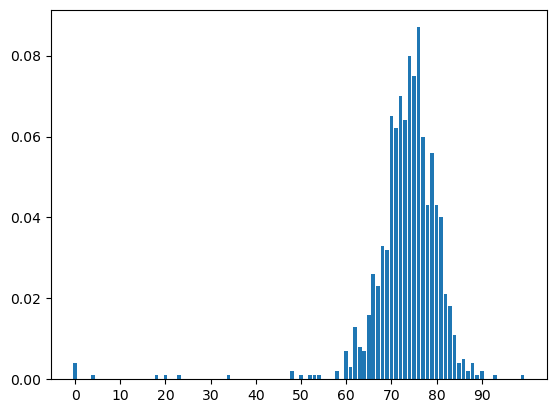

In [100]:
# Plot the PMF of the sample median
plt.bar(pmf2.index, pmf2.values)
plt.xticks(range(0, 100, 10))
plt.show()

##### Plot the distribution of the expected mean

In [95]:
# Construct the PMF of the sample median
pmf1 = result1.value_counts().sort_index() / result1.value_counts().sum()
pmf1.head()

33.0    0.001
33.6    0.001
33.8    0.001
36.2    0.001
36.8    0.001
Name: count, dtype: float64

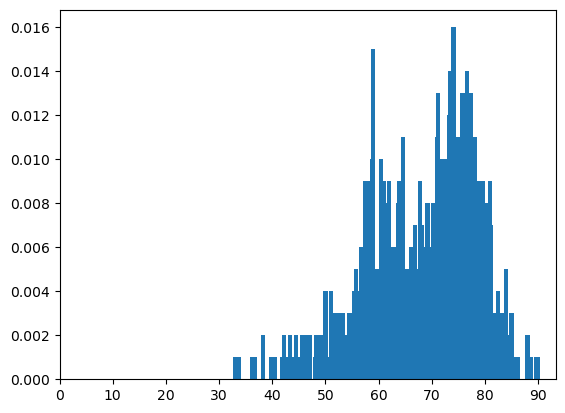

In [101]:
# Plot the PMF of the sample median
plt.bar(pmf1.index, pmf1.values)
plt.xticks(range(0, 100, 10))
plt.show()

### The difference between the expected median and the expected mean:

The distribution of the sample median is more clustered, however the distribution of the sample mean is more dispersed. 

### Question e

I would use the median to assign scores. The large variance of mean brings much uncertanty to the score, while the more clustered mean makes the grade more consistent and fair